# Economics S5040: Dynamic Stochastic Modeling
## Problem Set 3 — Answer Key

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

## Problem 1

### (a)
\(A\) is \(3\times 3\) and \(x\) is \(3\times 1\). Thus \(Ax\) is defined and is \(3\times 1\).
If \(x\) is a column vector, \(xA\) is not defined because the inner dimensions, 1 and 3, do not agree.

In [2]:
A = np.array([[0.10, 0.20, 0.00],
              [0.30, 0.10, 0.20],
              [0.00, 0.20, 0.40]])
x = np.array([100, 200, 300])

Ax = A @ x
Ax

array([ 50., 110., 160.])

By hand,
\[
Ax=
\begin{pmatrix}
.10(100)+.20(200)+0(300)\\
.30(100)+.10(200)+.20(300)\\
0(100)+.20(200)+.40(300)
\end{pmatrix}
=
\begin{pmatrix}50\\110\\160\end{pmatrix}.
\]
Each entry is the dot product of one row of \(A\) with \(x\).

In [3]:
A * x

array([[ 10.,  40.,   0.],
       [ 30.,  20.,  60.],
       [  0.,  40., 120.]])

`A * x` broadcasts `x` across the rows and multiplies entries element by element. It is not the row-by-column operation that combines inputs into each output.

In [4]:
B = np.array([[1, 2, 0],
              [0, 1, 1]])

BA = B @ A
print("BA shape:", BA.shape)
print(BA)

# A @ B is not defined: (3x3)(2x3) has incompatible inner dimensions.
try:
    print(A @ B)
except ValueError as e:
    print("A @ B fails:", e)

BA shape: (2, 3)
[[0.7 0.4 0.4]
 [0.3 0.3 0.6]]
A @ B fails: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)


The row-by-column rule forms each output entry by pairing one row from the left matrix with one column from the right matrix, multiplying corresponding entries, and adding those products.

## Problem 2

In [5]:
f = lambda x: np.exp(x**2)
mu, err = quad(f, 0, 1)
mu

1.4626517459071817

In [6]:
Ns = [10, 100, 1_000, 10_000, 100_000]
rng = np.random.default_rng(5040)

rows = []
for N in Ns:
    draws = rng.uniform(0, 1, N)
    est = np.mean(np.exp(draws**2))
    rows.append((N, est, abs(est-mu)))

for row in rows:
    print(row)

(10, np.float64(1.4133940838033319), np.float64(0.04925766210384985))
(100, np.float64(1.4165588254876544), np.float64(0.046092920419527283))
(1000, np.float64(1.4699424242292234), np.float64(0.007290678322041666))
(10000, np.float64(1.465188339123024), np.float64(0.00253659321584232))
(100000, np.float64(1.4605572341737139), np.float64(0.002094511733467863))


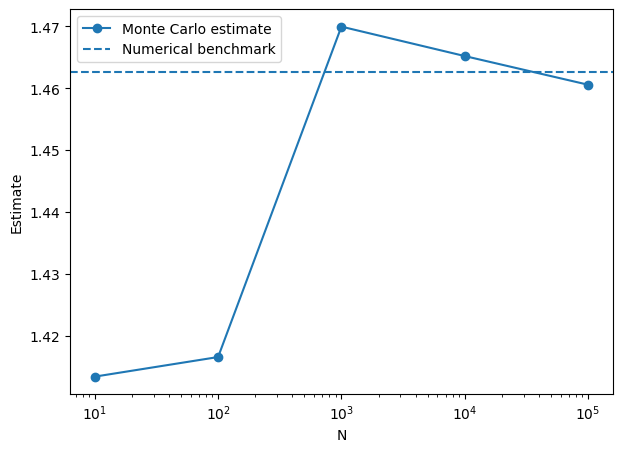

In [7]:
N_arr = np.array([r[0] for r in rows])
est_arr = np.array([r[1] for r in rows])

plt.figure(figsize=(7,5))
plt.plot(N_arr, est_arr, marker='o', label='Monte Carlo estimate')
plt.axhline(mu, linestyle='--', label='Numerical benchmark')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('Estimate')
plt.legend()
plt.show()

The LLN is a convergence statement, not a claim that every larger sample must be closer to the truth. Sampling error remains random, so a larger sample can occasionally give a worse estimate.

In [8]:
rng = np.random.default_rng(5040)
replications = 1000
sd_results = {}

for N in [100, 1_000, 10_000]:
    estimates = np.empty(replications)
    for r in range(replications):
        X = rng.uniform(0, 1, N)
        estimates[r] = np.mean(np.exp(X**2))
    sd_results[N] = estimates.std(ddof=1)

sd_results

{100: np.float64(0.0473120290147015),
 1000: np.float64(0.014604844606236032),
 10000: np.float64(0.004693845920306094)}

Monte Carlo standard error is proportional to \(1/\sqrt{N}\). Thus multiplying \(N\) by 100 should reduce the standard deviation of the estimator by about a factor of 10. The simulated values should be close to this relationship, subject to sampling variation across the 1,000 replications.

## Problem 3

In [9]:
P = np.array([[0.90, 0.10],
              [0.40, 0.60]])

print(P.sum(axis=1))
P2 = P @ P
P2

[1. 1.]


array([[0.85, 0.15],
       [0.6 , 0.4 ]])

The rows are nonnegative and sum to one. \(P_{EE}=0.90\), \(P_{EU}=0.10\), \(P_{UE}=0.40\), and \(P_{UU}=0.60\).

For an employed worker to be unemployed two periods later, the intermediate state can be either employed or unemployed:
\[
(P^2)_{EU}=P_{EE}P_{EU}+P_{EU}P_{UU}=.9(.1)+.1(.6)=.15.
\]

In [10]:
P10 = np.linalg.matrix_power(P, 10)
P10

array([[0.80019531, 0.19980469],
       [0.79921875, 0.20078125]])

The first-row, second-column entry is the ten-period unemployment probability conditional on employment today; the second-row, second-column entry is the same probability conditional on unemployment today.

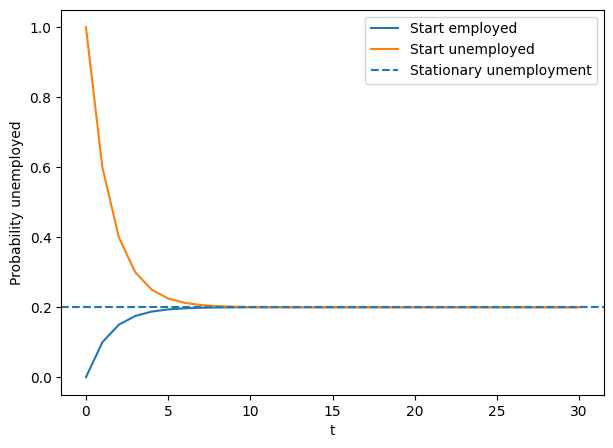

In [11]:
ts = np.arange(31)
paths = {}

for name, psi0 in {"Start employed": np.array([1.,0.]),
                   "Start unemployed": np.array([0.,1.])}.items():
    paths[name] = np.array([psi0 @ np.linalg.matrix_power(P, t) for t in ts])

plt.figure(figsize=(7,5))
for name, path in paths.items():
    plt.plot(ts, path[:,1], label=name)
plt.axhline(0.2, linestyle='--', label='Stationary unemployment')
plt.xlabel('t')
plt.ylabel('Probability unemployed')
plt.legend()
plt.show()

Let \(\psi^*=(e,u)\). Stationarity and adding up require
\[
u=.10e+.60u,\qquad e+u=1.
\]
Hence \(u=.20\) and \(e=.80\), so \(\psi^*=(.8,.2)\).

In [12]:
psi_star = np.array([0.8, 0.2])
print(psi_star @ P)
print(psi_star)

[0.8 0.2]
[0.8 0.2]


Both initial distributions converge to the same stationary distribution for this chain. Individuals continue switching states even when the cross-sectional distribution is constant.

## Problem 4

In [13]:
def simulate_employment(P, T, initial_state=0, seed=5040):
    rng = np.random.default_rng(seed)
    history = np.empty(T, dtype=int)
    history[0] = initial_state
    for t in range(1, T):
        history[t] = rng.choice([0, 1], p=P[history[t-1]])
    return history

h = simulate_employment(P, 100_000)
freq = np.bincount(h, minlength=2) / len(h)
freq

array([0.80042, 0.19958])

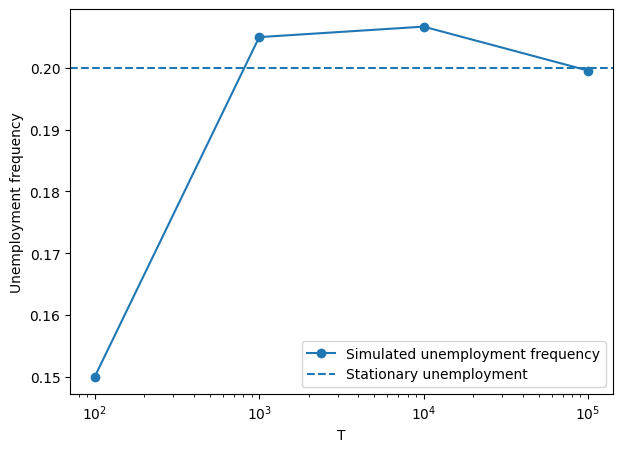

In [14]:
Ts = np.array([100, 1_000, 10_000, 100_000])
u_freq = []

for T in Ts:
    h = simulate_employment(P, T, seed=5040)
    u_freq.append(np.mean(h == 1))

plt.figure(figsize=(7,5))
plt.plot(Ts, u_freq, marker='o', label='Simulated unemployment frequency')
plt.axhline(0.2, linestyle='--', label='Stationary unemployment')
plt.xscale('log')
plt.xlabel('T')
plt.ylabel('Unemployment frequency')
plt.legend()
plt.show()

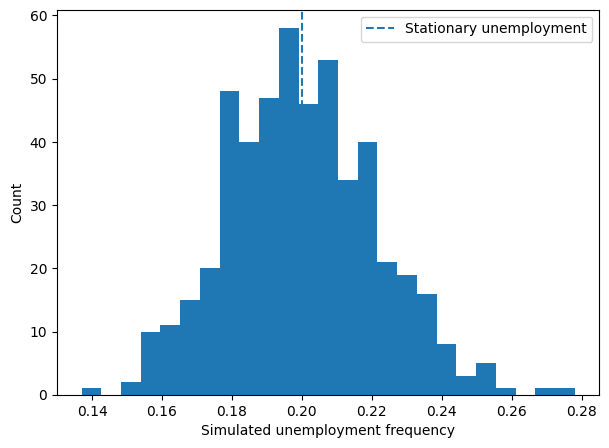

0.19984200000000002 0.0212408895005258


In [15]:
freqs = np.empty(500)
for r in range(500):
    h = simulate_employment(P, 1000, seed=5040+r)
    freqs[r] = np.mean(h == 1)

plt.figure(figsize=(7,5))
plt.hist(freqs, bins=25)
plt.axvline(0.2, linestyle='--', label='Stationary unemployment')
plt.xlabel('Simulated unemployment frequency')
plt.ylabel('Count')
plt.legend()
plt.show()

print(freqs.mean(), freqs.std(ddof=1))

The simulated history is random because each transition is drawn from the relevant row of \(P\). Long-run sample frequencies approximate the stationary probabilities. This is Monte Carlo logic applied to a dependent sequence rather than independent draws.

## Problem 5

In [16]:
P3 = np.array([[0.70, 0.25, 0.05],
               [0.10, 0.80, 0.10],
               [0.05, 0.25, 0.70]])
y = np.array([80., 100., 130.])

psi_low = np.array([1.,0.,0.])
for t in [1,2,10]:
    print(t, psi_low @ np.linalg.matrix_power(P3,t))

1 [0.7  0.25 0.05]
2 [0.5175 0.3875 0.095 ]
10 [0.22965719 0.55414836 0.21619445]


\(P_{13}=.05\) is the probability of moving from low productivity today to high productivity tomorrow. \(P_{22}=.80\) is the probability that normal productivity persists. \(P_{31}=.05\) is the probability of moving from high to low.

In [17]:
# Solve stationary distribution by replacing one equation with the adding-up condition.
n = P3.shape[0]
M = P3.T - np.eye(n)
M[-1,:] = 1
b = np.zeros(n)
b[-1] = 1
psi3 = np.linalg.solve(M,b)

print("stationary:", psi3)
print("sum:", psi3.sum())
print("psi P:", psi3 @ P3)

ybar = psi3 @ y
print("long-run mean output:", ybar)

stationary: [0.22222222 0.55555556 0.22222222]
sum: 1.0
psi P: [0.22222222 0.55555556 0.22222222]
long-run mean output: 102.22222222222223


The product \(\psi^*y\) is a row vector times a column vector:
\[
\bar y=\sum_j \psi_j^* y_j.
\]
That is exactly the probability-weighted average, or expectation, of output under the stationary distribution.

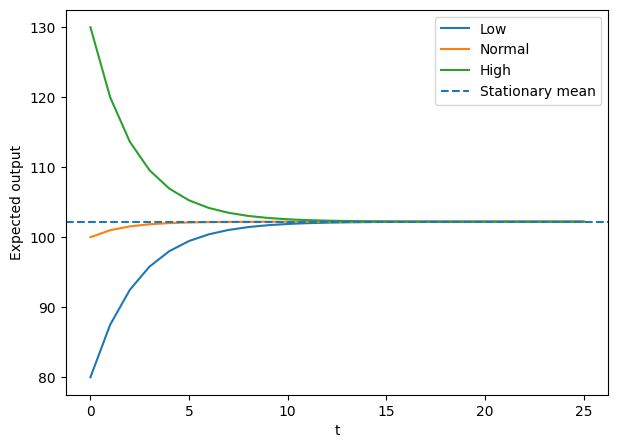

In [18]:
ts = np.arange(26)
initials = {
    "Low": np.array([1.,0.,0.]),
    "Normal": np.array([0.,1.,0.]),
    "High": np.array([0.,0.,1.])
}

plt.figure(figsize=(7,5))
for name, psi0 in initials.items():
    ey = np.array([(psi0 @ np.linalg.matrix_power(P3,t)) @ y for t in ts])
    plt.plot(ts, ey, label=name)

plt.axhline(ybar, linestyle='--', label='Stationary mean')
plt.xlabel('t')
plt.ylabel('Expected output')
plt.legend()
plt.show()

In [19]:
P3_tilde = np.array([[0.90, 0.05, 0.05],
                     [0.10, 0.80, 0.10],
                     [0.05, 0.05, 0.90]])

M = P3_tilde.T - np.eye(3)
M[-1,:] = 1
b = np.array([0.,0.,1.])
psi_tilde = np.linalg.solve(M,b)
ybar_tilde = psi_tilde @ y

print(psi_tilde)
print(ybar_tilde)

[0.4 0.2 0.4]
104.0


Greater persistence alone does not determine whether mean output rises or falls. What matters is how the transition changes the stationary probabilities across states and the output associated with those states. Persistence can increase the long-run weight on both low and high states.

## Problem 6

In [20]:
exact20 = psi_low @ np.linalg.matrix_power(P3,20)
exact20

array([0.22231463, 0.55555199, 0.22213338])

In [21]:
def terminal_state(P, horizon, rng, initial_state=0):
    state = initial_state
    states = np.arange(P.shape[0])
    for _ in range(horizon):
        state = rng.choice(states, p=P[state])
    return state

rng = np.random.default_rng(5040)
Msim = 100_000
terminal = np.empty(Msim, dtype=int)

for m in range(Msim):
    terminal[m] = terminal_state(P3, 20, rng, initial_state=0)

sim20 = np.bincount(terminal, minlength=3) / Msim
print("exact:", exact20)
print("simulated:", sim20)
print("error:", sim20-exact20)

exact: [0.22231463 0.55555199 0.22213338]
simulated: [0.22181 0.55711 0.22108]
error: [-0.00050463  0.00155801 -0.00105338]


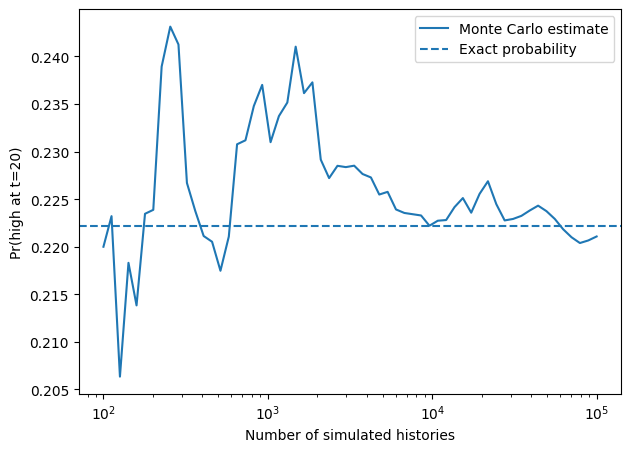

In [22]:
rng = np.random.default_rng(5040)
Mmax = 100_000
high_indicators = np.empty(Mmax)

for m in range(Mmax):
    high_indicators[m] = (terminal_state(P3, 20, rng, 0) == 2)

checkpoints = np.unique(np.logspace(2,5,60).astype(int))
estimates = np.array([high_indicators[:M].mean() for M in checkpoints])
exact_high = exact20[2]

plt.figure(figsize=(7,5))
plt.plot(checkpoints, estimates, label='Monte Carlo estimate')
plt.axhline(exact_high, linestyle='--', label='Exact probability')
plt.xscale('log')
plt.xlabel('Number of simulated histories')
plt.ylabel('Pr(high at t=20)')
plt.legend()
plt.show()

Matrix multiplication computes the finite-state probability distribution exactly (up to numerical rounding). Simulation replaces that calculation with sample frequencies from randomly generated histories. Here exact multiplication is preferable. In larger models, however, the state space can be enormous or continuous, making exact distribution calculations infeasible; simulation can then remain practical.

## What surprised me?

Student-specific response.